<a href="https://colab.research.google.com/github/jyryu3161/chembigdata/blob/main/lec10_BBBP_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BBBP 데이터 EDA


## 1. 준비: 도구와 용어

`pandas`는 표, `seaborn`은 그래프, `RDKit`은 분자 구조를 다룹니다. 첫 셀은 RDKit이 없거나 버전이 다를 때 설치합니다. 설치 후 가져오기 오류가 나면 Colab 세션을 다시 시작하고 처음부터 실행하세요.

| 용어 | 이 수업에서의 의미 |
|---|---|
| 샘플 | CSV의 한 행. 중복이 있으므로 반드시 서로 다른 분자는 아님 |
| SMILES | 원자와 결합을 문자열로 표현한 방식 |
| target | 예측하고 싶은 정답, 이 파일에서는 0 또는 1 |
| descriptor | 구조에서 계산한 숫자 특성 |
| EDA | 표와 그림을 통해 데이터의 품질과 패턴을 살펴보는 탐색적 분석 |

**라벨 해석:** 수업에서는 일반적인 BBBP 관례에 따라 1을 투과, 0을 비투과로 해석합니다. 다만 첨부 CSV에는 라벨 정의·실험 조건·출처 메타데이터가 없으므로 이 매핑은 데이터 제공자의 설명으로 최종 확인해야 합니다. 그래프에는 확실히 관측한 값인 `target 0/1`을 표시합니다.

In [16]:
import sys, subprocess, importlib.metadata
RDKIT_VERSION = "2026.9.1"
try:
    installed = importlib.metadata.version("rdkit")
except importlib.metadata.PackageNotFoundError:
    installed = None
if installed != RDKIT_VERSION:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           f"rdkit=={RDKIT_VERSION}"])
print("RDKit package:", importlib.metadata.version("rdkit"))

RDKit package: 2026.9.1


In [2]:
from pathlib import Path
import hashlib, json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import rdkit
from rdkit import Chem, rdBase
from rdkit.Chem import Descriptors, Draw
from rdkit.Chem.Scaffolds import MurckoScaffold
from IPython.display import display

SEED = 42
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {0: "#3876B9", 1: "#DA8A24"}
pd.set_option("display.max_colwidth", 80)
print({"Python": platform.python_version(), "pandas": pd.__version__,
       "numpy": np.__version__, "RDKit": rdkit.__version__,
       "seaborn": sns.__version__})
# 그래프의 제목과 축은 영어: Colab 기본 폰트에서도 글자가 깨지지 않게 합니다.

{'Python': '3.13.16', 'pandas': '2.2.3', 'numpy': '2.1.3', 'RDKit': '2026.09.1', 'seaborn': '0.13.2'}


## 2. 파일을 읽고 표의 단위를 확인하기

파일 이름은 `train.csv`로 준비합니다. 이미 Colab 파일 영역에 있으면 그대로 읽고, 없으면 업로드 창이 열립니다. 다른 이름으로 저장했다면 아래 `DATA_PATH`를 수정하세요.

`sample_id`는 행 식별자이며 분자의 성질이 아닙니다. 이후 모델의 입력 특성에 넣지 않습니다. 파일 해시는 같은 파일을 분석했는지 확인하는 지문입니다. CSV의 문자열은 데이터로만 읽으며 실행하지 않습니다.

In [3]:
DATA_PATH = Path("train.csv")
if not DATA_PATH.exists():
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError("train.csv를 노트북 작업 폴더에 넣거나 DATA_PATH를 수정하세요.")
    uploaded = files.upload()
    if DATA_PATH.name not in uploaded:
        raise FileNotFoundError("train.csv를 선택한 뒤 이 셀을 다시 실행하세요.")

file_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
raw = pd.read_csv(DATA_PATH, dtype={"sample_id": "string", "SMILES": "string"})
required = {"sample_id", "SMILES", "target"}
assert required.issubset(raw.columns), f"필수 컬럼 누락: {required - set(raw.columns)}"
assert len(raw) > 0, "빈 파일입니다."
print(f"행 수: {len(raw):,}, 열 수: {raw.shape[1]}")
print("SHA-256:", file_hash)
display(raw.head())
raw.info()

Saving train.csv to train.csv
행 수: 1,421, 열 수: 3
SHA-256: 366c594fbb112b02094e9d859cd7afaca4a6c57d34746a22886db765ac3c65e6


,sample_id,SMILES,target
0,train_0001,N[C@@H](Cc1ccc(O)c(O)c1)C(=O)O,0
1,train_0002,COC(=O)[C@@]1(O)CC[C@H]2C3CCC(=O)C4C(=O)C=CC4(C)[C@H]3C(O)CC21C,1
2,train_0003,CN(C)CCc1ccccn1,1
3,train_0004,CC(C)NCC(O)COc1ccc(CC(N)=O)cc1,0
4,train_0005,O=C(Nc1ccc(O)cc1)C(Cl)(Cl)Cl,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1421 entries, 0 to 1420
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   sample_id  1421 non-null   string
 1   SMILES     1421 non-null   string
 2   target     1421 non-null   int64 
dtypes: int64(1), string(2)
memory usage: 33.4 KB


**읽는 법:** `head()`는 처음 몇 행을, `info()`는 데이터형과 비결측 개수를 보여줍니다. `SMILES`가 문자열인 것은 오류가 아닙니다. 숫자 특성을 계산하려면 먼저 구조로 해석해야 합니다.

✍️ **질문 1:** 1,421행이면 서로 다른 분자가 1,421개라고 말할 수 있을까요? 이유를 적어보세요.

## 3. 결측치·라벨·문자열 중복

결측치와 공백 문자열을 함께 확인합니다. 라벨이 없는 행에 임의로 0을 넣으면 잘못된 정답을 만들게 됩니다. 원본 `raw`는 보존하고 분석용 복사본을 사용합니다.

In [4]:
df = raw.copy()
for col in ["sample_id", "SMILES"]:
    df[col] = df[col].str.strip().replace("", pd.NA)

label_numeric = pd.to_numeric(df["target"], errors="coerce")
valid_label = label_numeric.isin([0, 1])
df["target"] = label_numeric.where(valid_label).astype("Int64")
display(pd.DataFrame({"dtype": raw.dtypes.astype(str),
                      "missing_original": raw.isna().sum(),
                      "missing_after_check": df[raw.columns].isna().sum()}))
print("0/1이 아니거나 비어 있는 라벨:", int((~valid_label).sum()))
print("원본 전체 행 중복(첫 행 제외):", int(raw.duplicated().sum()))
print("중복 ID(결측 제외, 첫 행 제외):", int(df.sample_id.dropna().duplicated().sum()))
print("중복 SMILES 문자열(공백 정리 후, 첫 행 제외):", int(df.SMILES.dropna().duplicated().sum()))
display(df.loc[df.SMILES.notna() & df.SMILES.duplicated(keep=False)]
        .sort_values("SMILES").head(10))

,dtype,missing_original,missing_after_check
sample_id,string,0,0
SMILES,string,0,0
target,int64,0,0


0/1이 아니거나 비어 있는 라벨: 0
원본 전체 행 중복(첫 행 제외): 0
중복 ID(결측 제외, 첫 행 제외): 0
중복 SMILES 문자열(공백 정리 후, 첫 행 제외): 37


,sample_id,SMILES,target
710,train_0711,CC(=O)Nc1ccc(O)cc1,1
1219,train_1220,CC(=O)Nc1ccc(O)cc1,1
1135,train_1136,CC(=O)Oc1ccccc1C(=O)O,0
420,train_0421,CC(=O)Oc1ccccc1C(=O)O,1
786,train_0787,CC(C)(C)OC(=O)CCCc1ccc(N(CCCl)CCCl)cc1,1
378,train_0379,CC(C)(C)OC(=O)CCCc1ccc(N(CCCl)CCCl)cc1,1
1231,train_1232,CC(C)c1nc(-c2ncn3c2CN(C)C(=O)c2c(Cl)cccc2-3)no1,1
485,train_0486,CC(C)c1nc(-c2ncn3c2CN(C)C(=O)c2c(Cl)cccc2-3)no1,1
783,train_0784,CC1COc2c(N3CCN(C)CC3)c(F)cc3c(=O)c(C(=O)O)cn1c23,1
886,train_0887,CC1COc2c(N3CCN(C)CC3)c(F)cc3c(=O)c(C(=O)O)cn1c23,1


## 4. 정답 비율: 정확도만 보면 생기는 문제

클래스는 정답의 종류입니다. 클래스 불균형은 한 종류가 더 많은 상태를 뜻합니다. 비율을 계산할 때 분모는 **유효한 라벨이 있는 행 수**입니다. 아직 구조 중복을 제거하지 않은 원본 기준 분포입니다.

,n,percent
target,,
0,341,24.0
1,1080,76.0


다수 클래스만 답하는 기준선의 이 데이터 내 정확도: 76.00%


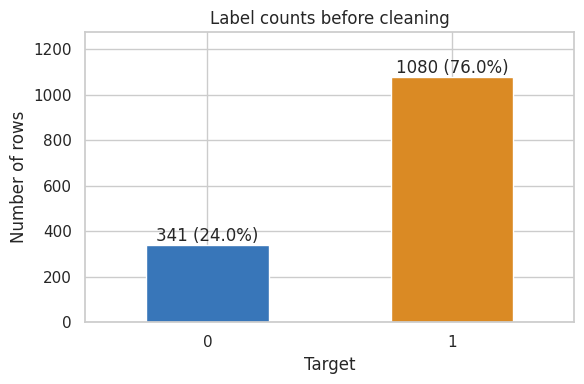

In [5]:
counts = df.target.value_counts().reindex([0, 1], fill_value=0).astype(int)
assert counts.sum() > 0, "분석 가능한 0/1 라벨이 없습니다."
class_table = pd.DataFrame({"n": counts, "percent": 100 * counts / counts.sum()})
display(class_table.round(2))
majority_accuracy = counts.max() / counts.sum()
print(f"다수 클래스만 답하는 기준선의 이 데이터 내 정확도: {majority_accuracy:.2%}")
ax = counts.plot.bar(color=[PALETTE[0], PALETTE[1]], rot=0, figsize=(6, 4))
ax.set(xlabel="Target", ylabel="Number of rows", title="Label counts before cleaning")
for i, n in enumerate(counts):
    ax.text(i, n, f"{n} ({n/counts.sum():.1%})", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.18)
plt.tight_layout(); plt.show()

**생각해 보기:** 약 76%의 정확도를 얻어도 모든 분자에 1만 답했다면 target 0을 하나도 찾지 못한 것입니다. 이 값은 현재 데이터에서 계산한 단순 기준선이며 미래 데이터의 성능은 아닙니다.

다음 수업에서는 혼동행렬, 클래스별 precision/recall, balanced accuracy를 함께 봅니다. ROC-AUC와 average precision(AP)도 확률 점수에 대한 평가에 사용할 수 있습니다. 양성을 1로 정의했을 때 AP는 양성 비율의 영향을 받으므로 양성 비율도 함께 보고합니다.

## 5. SMILES를 분자로 읽기

`MolFromSmiles`는 SMILES를 구조로 변환합니다. 실패한 문자열과 원자가 없는 구조는 별도로 기록합니다. 성공했다고 해서 해당 실험·라벨이 과학적으로 검증되었다는 뜻은 아닙니다.

Canonical SMILES는 같은 구조 표현을 비교하기 위한 대표 문자열입니다. 여기서는 **입체화학을 보존**합니다. 염 제거·중성화·토토머 통일은 하지 않으므로, 모든 화학적 동등성을 해결한 식별자는 아닙니다.

In [6]:
def parse_smiles(value):
    if pd.isna(value):
        return None
    # 대량 파싱 메시지는 숨기지만 실패 행은 아래 표와 CSV에 남깁니다.
    with rdBase.BlockLogs():
        mol = Chem.MolFromSmiles(str(value))
    return mol if mol is not None and mol.GetNumAtoms() > 0 else None

df["mol"] = df.SMILES.map(parse_smiles)
df["valid_smiles"] = df.mol.map(lambda m: m is not None)
df["canonical_smiles"] = df.mol.map(
    lambda m: Chem.MolToSmiles(m, canonical=True, isomericSmiles=True)
    if m is not None else None)
df["n_fragments"] = df.mol.map(lambda m: len(Chem.GetMolFrags(m)) if m is not None else np.nan)
invalid_smiles = df.loc[~df.valid_smiles, ["sample_id", "SMILES", "target"]]
print("구조 해석 성공:", int(df.valid_smiles.sum()))
print("구조 해석 실패 또는 빈 구조:", len(invalid_smiles))
print("여러 조각으로 이루어진 구조:", int((df.n_fragments > 1).sum()))
display(invalid_smiles.head(10))
display(df.loc[df.n_fragments > 1, ["sample_id", "SMILES", "n_fragments"]].head())

구조 해석 성공: 1421
구조 해석 실패 또는 빈 구조: 0
여러 조각으로 이루어진 구조: 77


,sample_id,SMILES,target


,sample_id,SMILES,n_fragments
33,train_0034,C[C@]12C[C@H](O)[C@H]3[C@@H](CCC4=CC(=O)C=C[C@@]43C)[C@@H]1CC[C@]2(O)C(=O)CO...,2
98,train_0099,C[N+]1(C)CCCC(OC(=O)C(O)(c2ccccc2)c2ccccc2)C1.[Br-],2
178,train_0179,C[C@]12C[C@H](O)[C@H]3[C@@H](CCC4=CC(=O)CC[C@@]43C)[C@@H]1CC[C@]2(O)C(=O)COC...,2
183,train_0184,O=C(O)CCCCCC[NH2+]C1c2ccccc2CCc2ccccc21.[Cl-],2
186,train_0187,CN(C)[C@@H]1C(=O)/C(=C(/N)O)C(=O)[C@@]2(O)C(=O)C3=C(O)c4c(O)ccc(Cl)c4[C@@](C...,3


**여러 조각이란?** SMILES의 `.`은 연결되지 않은 조각을 나타냅니다. 염 형태 등이 포함될 수 있습니다. 이 수업에서는 임의로 조각을 삭제하지 않고 전체 입력 구조의 특성을 계산합니다. 따라서 분자량이나 전하는 조각 처리 규칙에 영향을 받을 수 있습니다.

## 6. 같은 구조에 다른 라벨이 붙었을까?

문자열이 달라도 구조가 같을 수 있습니다. 정규화한 구조로 묶고, 각 묶음에서 서로 다른 라벨 개수를 셉니다. 두 라벨이 함께 있으면 **라벨 충돌**입니다. 충돌은 측정 조건 차이나 데이터 정리 문제일 수 있으므로 다수결로 정답을 확정하지 않습니다.

In [7]:
valid = df.loc[df.valid_smiles & df.target.notna()].copy()
valid["target"] = valid.target.astype(int)
structure_groups = valid.groupby("canonical_smiles").agg(
    n_rows=("target", "size"), n_labels=("target", "nunique"))
conflict_keys = structure_groups.index[structure_groups.n_labels > 1]
conflicts = valid.loc[valid.canonical_smiles.isin(conflict_keys)].copy()
print("유효 구조·라벨 행:", len(valid))
print("정규화 구조 기준 중복 초과 행:", len(valid) - len(structure_groups))
print("라벨 충돌 구조 수:", len(conflict_keys))
display(conflicts[["sample_id", "SMILES", "canonical_smiles", "target"]].head(12))

# 교육용 정책: 충돌 구조는 모든 행을 보류, 동일 구조·동일 라벨은 첫 행만 유지
nonconflict = valid.loc[~valid.canonical_smiles.isin(conflict_keys)].copy()
clean = nonconflict.drop_duplicates("canonical_smiles", keep="first").copy()
clean = clean.reset_index(drop=True)
flow = pd.DataFrame({
    "stage": ["Raw rows", "Valid structure + label", "After conflict holdout", "Unique structures"],
    "n_rows": [len(raw), len(valid), len(nonconflict), len(clean)]})
display(flow)
assert len(clean) > 0, "정리 후 데이터가 없습니다."
assert clean.canonical_smiles.is_unique
before_after = pd.DataFrame({
    "raw_n": counts,
    "clean_n": clean.target.value_counts().reindex([0, 1], fill_value=0)})
before_after["raw_percent"] = 100 * before_after.raw_n / before_after.raw_n.sum()
before_after["clean_percent"] = 100 * before_after.clean_n / before_after.clean_n.sum()
display(before_after.round(2))

유효 구조·라벨 행: 1421
정규화 구조 기준 중복 초과 행: 37
라벨 충돌 구조 수: 7


,sample_id,SMILES,canonical_smiles,target
0,train_0001,N[C@@H](Cc1ccc(O)c(O)c1)C(=O)O,N[C@@H](Cc1ccc(O)c(O)c1)C(=O)O,0
73,train_0074,CN1C2CCC1CC(OC(=O)C(CO)c1ccccc1)C2,CN1C2CCC1CC(OC(=O)C(CO)c1ccccc1)C2,1
225,train_0226,C[C@H]1C[C@H]2[C@@H]3CC[C@](O)(C(=O)CO)[C@@]3(C)C[C@H](O)[C@@H]2[C@@]2(C)C=C...,C[C@H]1C[C@@H]2[C@H]([C@@H](O)C[C@@]3(C)[C@H]2CC[C@]3(O)C(=O)CO)[C@@]2(C)C=C...,1
411,train_0412,N[C@@H](Cc1ccc(O)c(O)c1)C(=O)O,N[C@@H](Cc1ccc(O)c(O)c1)C(=O)O,1
420,train_0421,CC(=O)Oc1ccccc1C(=O)O,CC(=O)Oc1ccccc1C(=O)O,1
442,train_0443,COc1cc(NCc2ccc3nc(N)nc(N)c3c2C)cc(OC)c1OC,COc1cc(NCc2ccc3nc(N)nc(N)c3c2C)cc(OC)c1OC,1
451,train_0452,CCOC(=O)N1CCC(=C2c3ccc(Cl)cc3CCc3cccnc32)CC1,CCOC(=O)N1CCC(=C2c3ccc(Cl)cc3CCc3cccnc32)CC1,0
576,train_0577,COc1ccc2c(c1)c(CC(=O)O)c(C)n2C(=O)c1ccc(Cl)cc1,COc1ccc2c(c1)c(CC(=O)O)c(C)n2C(=O)c1ccc(Cl)cc1,1
680,train_0681,CN1C2CCC1CC(OC(=O)C(CO)c1ccccc1)C2,CN1C2CCC1CC(OC(=O)C(CO)c1ccccc1)C2,0
809,train_0810,COc1ccc2c(c1)c(CC(=O)O)c(C)n2C(=O)c1ccc(Cl)cc1,COc1ccc2c(c1)c(CC(=O)O)c(C)n2C(=O)c1ccc(Cl)cc1,0


,stage,n_rows
0,Raw rows,1421
1,Valid structure + label,1421
2,After conflict holdout,1407
3,Unique structures,1377


,raw_n,clean_n,raw_percent,clean_percent
target,,,,
0,341,330,24.0,23.97
1,1080,1047,76.0,76.03


**정책의 한계:** 중복이 독립적인 반복 실험일 수도 있습니다. 이 파일에는 실험 정보가 없어 수업에서는 구조당 한 행으로 탐색합니다. 충돌 행 보류는 라벨의 영향을 받는 선택이므로, 실제 연구에서는 원자료를 검토하고 정책과 제외 건수를 보고해야 합니다. 기존 벤치마크의 평가 데이터를 임의로 정리하여 점수를 높여서는 안 됩니다.

✍️ **질문 2:** 문자열 중복 검사만 하면 놓치는 경우는 무엇인가요? 중복 제거 전후 클래스 비율도 비교해보세요.

## 7. 분자 그림과 숫자 특성 연결하기

두 클래스에서 최대 4개씩 무작위로 고릅니다. `random_state=42`는 재실행 시 같은 표본을 선택하기 위한 값입니다. 그림 몇 개만으로 클래스 전체를 대표할 수는 없습니다.

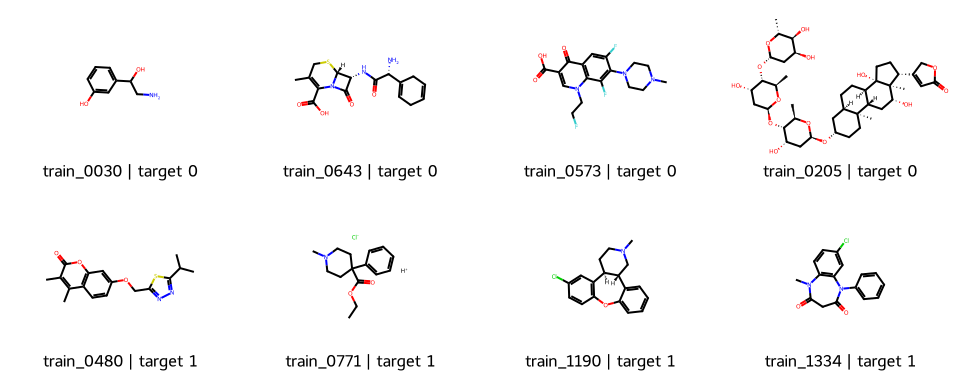

In [8]:
examples = pd.concat([g.sample(n=min(4, len(g)), random_state=SEED)
                      for _, g in clean.groupby("target")])
display(Draw.MolsToGridImage(
    examples.mol.tolist(), molsPerRow=4, subImgSize=(240, 190),
    legends=[f"{r.sample_id} | target {r.target}" for r in examples.itertuples()],
    useSVG=True))

## 8. 사람이 이해할 수 있는 분자 특성 만들기

| 특성 | 뜻 | 단위·해석 |
|---|---|---|
| MolWt | 평균 분자량 | 수치상 g/mol에 해당 |
| LogP | 계산된 옥탄올/물 분배계수의 로그 | 무차원, 지용성 관련; pH 의존 logD와 다름 |
| TPSA | 위상학적 극성 표면적 | Å², 구조 기반 극성 지표 |
| HBD / HBA | 수소결합 주개 / 받개 수 | 개수 |
| RotBonds | 회전 가능한 결합 수 | 유연성 관련 개수 |
| Rings | 고리 수 | 개수 |
| FormalCharge | 형식 전하의 합 | 정수, 생리 pH에서의 전하를 확정하지 않음 |

이 값들은 입력 구조로부터 계산한 요약입니다. 혈액–뇌 장벽 투과 여부를 직접 측정한 값이 아니며, 한 특성의 임계값만으로 정답을 결정할 수 없습니다.

In [9]:
descriptor_functions = {
    "MolWt": Descriptors.MolWt,
    "LogP": Descriptors.MolLogP,
    "TPSA": Descriptors.TPSA,
    "HBD": Descriptors.NumHDonors,
    "HBA": Descriptors.NumHAcceptors,
    "RotBonds": Descriptors.NumRotatableBonds,
    "Rings": Descriptors.RingCount,
    "FormalCharge": Chem.GetFormalCharge,
}
feature_cols = list(descriptor_functions)
descriptor_table = pd.DataFrame([
    {name: fn(mol) for name, fn in descriptor_functions.items()}
    for mol in clean.mol], index=clean.index)
eda = pd.concat([clean, descriptor_table], axis=1)
assert np.isfinite(eda[feature_cols].to_numpy(dtype=float)).all(), "특성 계산 결과를 확인하세요."
display(eda[["sample_id", "target"] + feature_cols].head())
display(eda[feature_cols].describe().T.round(2))

,sample_id,target,MolWt,LogP,TPSA,HBD,HBA,RotBonds,Rings,FormalCharge
0,train_0002,1,376.449,1.4281,100.90,2,6,1,4,0
1,train_0003,1,150.225,1.1857,16.13,0,2,3,1,0
2,train_0004,0,266.341,0.4521,84.58,3,4,8,1,0
3,train_0005,1,254.500,2.7009,49.33,2,2,1,1,0
4,train_0006,0,324.424,3.1732,45.59,1,4,4,5,0


,count,mean,std,min,25%,50%,75%,max
MolWt,1377.0,357.59,149.17,78.11,267.37,336.43,421.49,1736.18
LogP,1377.0,2.36,2.05,-8.42,1.33,2.58,3.74,10.81
TPSA,1377.0,73.67,58.69,0.00,35.83,58.20,94.83,530.87
HBD,1377.0,1.59,1.86,0.00,1.00,1.00,2.00,19.00
HBA,1377.0,4.65,3.25,0.00,3.00,4.00,6.00,28.00
RotBonds,1377.0,4.30,3.17,0.00,2.00,4.00,6.00,35.00
Rings,1377.0,3.14,1.45,1.00,2.00,3.00,4.00,14.00
FormalCharge,1377.0,0.00,0.06,-1.00,0.00,0.00,0.00,1.00


### 8-1. 전체 분포와 클래스별 분포

히스토그램은 값이 어느 범위에 많이 있는지 보여줍니다. 클래스 크기가 다르므로 각 클래스 안에서 면적이 1이 되도록 정규화하여 모양을 비교합니다. 밀도 축은 샘플 수나 투과 확률이 아닙니다.

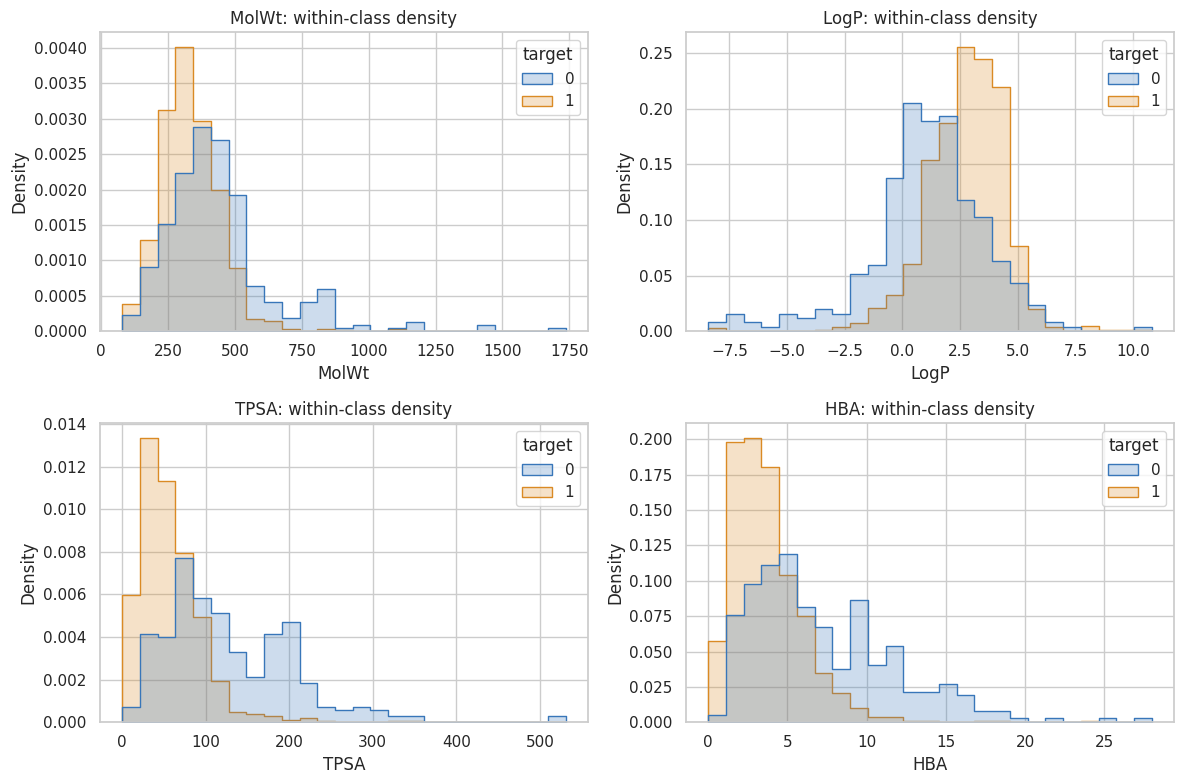

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, ["MolWt", "LogP", "TPSA", "HBA"]):
    sns.histplot(data=eda, x=col, hue="target", hue_order=[0, 1],
                 palette=PALETTE, bins=25, stat="density", common_norm=False,
                 element="step", alpha=0.25, ax=ax)
    ax.set_title(f"{col}: within-class density")
plt.tight_layout(); plt.show()

### 8-2. 중앙값과 상자그림

중앙값은 정렬했을 때 가운데 값입니다. 상자는 가운데 50%(Q1~Q3), 상자 안 선은 중앙값입니다. 수염 바깥 점은 관례적인 이상치 후보이며 오류라는 뜻은 아닙니다. 두 클래스의 중앙값이 달라도 분포가 겹치면 한 특성만으로 완벽하게 구분하기 어렵습니다.

MolWt           LogP          TPSA            HBD          HBA        \
        median    mean median  mean  median    mean median  mean median  mean   
target                                                                          
0       404.66  439.33   1.21  1.09  109.53  127.99    2.0  3.20    6.0  7.31   
1       316.16  331.83   2.90  2.76   49.41   56.55    1.0  1.08    3.0  3.81   

       RotBonds        Rings       FormalCharge       
         median  mean median  mean       median mean  
target                                                
0           5.0  5.40    3.0  3.29          0.0  0.0  
1           4.0  3.96    3.0  3.09          0.0  0.0

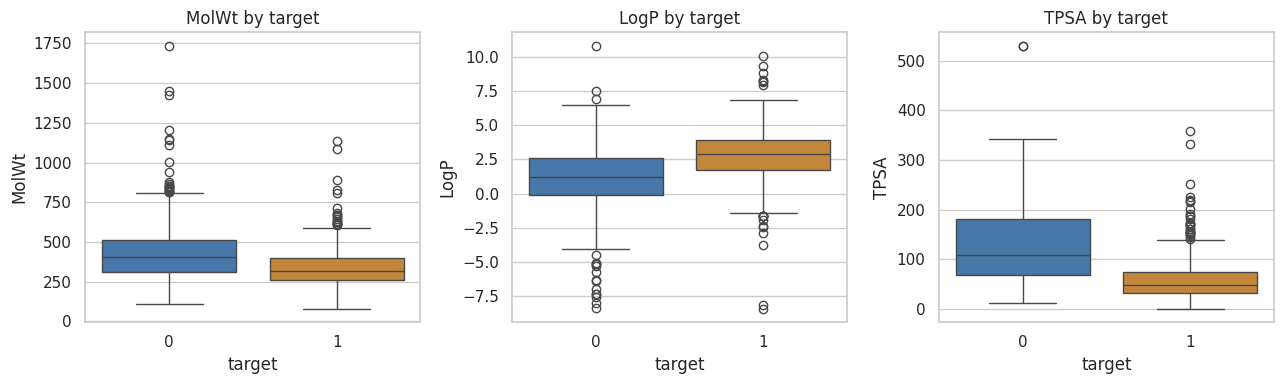

In [11]:
display(eda.groupby("target")[feature_cols].agg(["median", "mean"]).round(2))
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, ["MolWt", "LogP", "TPSA"]):
    sns.boxplot(data=eda, x="target", y=col, hue="target", order=[0, 1],
                palette=PALETTE, dodge=False, ax=ax)
    if ax.get_legend() is not None:
        ax.get_legend().remove()
    ax.set_title(f"{col} by target")
plt.tight_layout(); plt.show()

✍️ **질문 3:** TPSA의 클래스별 중앙값을 비교하고, 분포가 겹치는 구간도 찾아보세요. “TPSA가 낮으면 반드시 투과한다”라는 결론이 가능한가요?

### 8-3. 두 특성을 함께 보기

점 하나는 정리 후 분자 하나입니다. 클래스별 히스토그램과 달리 산점도에는 실제 개수 차이가 그대로 나타납니다. 겹친 점이 많을 수 있어 투명도를 적용합니다.

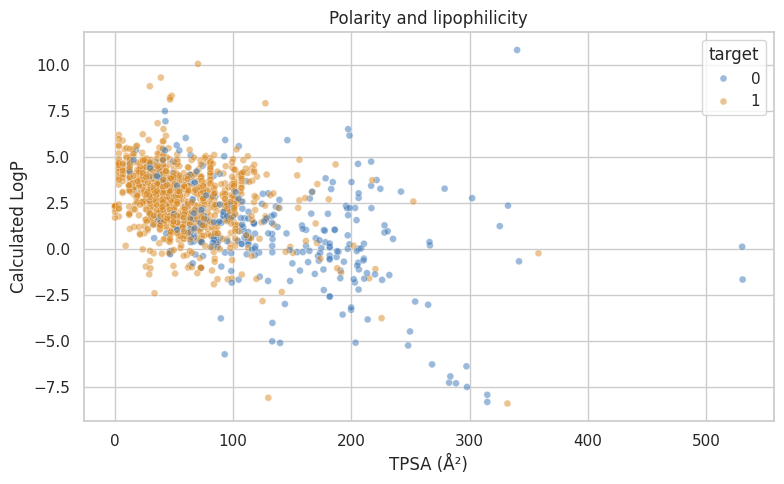

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=eda, x="TPSA", y="LogP", hue="target", hue_order=[0, 1],
                palette=PALETTE, alpha=0.5, s=25, ax=ax)
ax.set(title="Polarity and lipophilicity", xlabel="TPSA (Å²)", ylabel="Calculated LogP")
plt.tight_layout(); plt.show()

## 9. 특성끼리의 상관관계와 극단값

상관계수는 두 변수가 함께 변하는 정도를 -1~1로 요약합니다. 여기서는 값의 순서를 이용하는 **Spearman 상관계수**를 사용합니다. 0에 가까워도 모든 종류의 관계가 없다는 뜻은 아니며, 상관관계는 인과관계가 아닙니다. `target`과 ID는 이 특성 간 상관표에서 제외합니다.

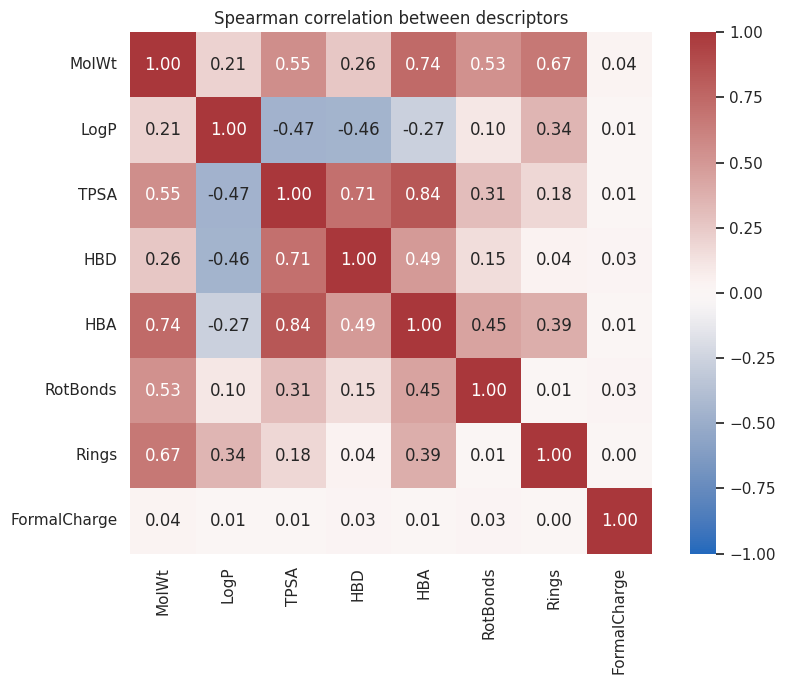

In [13]:
corr = eda[feature_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1,
            center=0, square=True, ax=ax)
ax.set_title("Spearman correlation between descriptors")
plt.tight_layout(); plt.show()